# Data Preprocessing – House Prices
Notebook thực hiện tiền xử lý dữ liệu và **so sánh trước/sau**:

1. Khám phá dữ liệu & chụp lại trạng thái **TRƯỚC** preprocessing
2. Xử lý **dữ liệu thiếu** (missing values)
3. Xử lý **giá trị bất thường** (anomalies – lỗi logic/không hợp lệ)
4. Xử lý **outlier** (loại điểm ngoại lai, capping IQR, giảm skew bằng log)
5. Mã hóa **Categorical data** (ordinal + one-hot)
6. **So sánh trước/sau** (shape, missing, skew, biểu đồ, hiệu năng mô hình)
7. Lưu dữ liệu đã xử lý

> Các file `sample_sub_*.csv`, `sample_submission.csv` chỉ là file nộp bài mẫu nên không cần tiền xử lý.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100); pd.set_option('display.width', 200)

DATA_DIR = '/mnt/user-data/uploads' if os.path.exists('/mnt/user-data/uploads/train.csv') else '.'
train_raw = pd.read_csv(f'{DATA_DIR}/train.csv')
test_raw  = pd.read_csv(f'{DATA_DIR}/test.csv')
print('train:', train_raw.shape, '| test:', test_raw.shape)
train_raw.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Khám phá dữ liệu (TRƯỚC preprocessing)

In [2]:
TARGET = 'SalePrice'
num_cols_raw = train_raw.select_dtypes(include='number').columns.drop(['Id', TARGET]).tolist()
cat_cols_raw = train_raw.select_dtypes(exclude='number').columns.tolist()
print(f'Numeric: {len(num_cols_raw)} cột | Categorical: {len(cat_cols_raw)} cột')
print('Dòng trùng lặp:', train_raw.duplicated().sum())

def missing_table(df):
    m = df.isna().sum(); m = m[m > 0].sort_values(ascending=False)
    return pd.DataFrame({'n_missing': m, 'pct': (m / len(df) * 100).round(2), 'dtype': df[m.index].dtypes.astype(str)})

mt = missing_table(train_raw)
print('Số cột có missing (train):', len(mt))
mt

Numeric: 36 cột | Categorical: 43 cột
Dòng trùng lặp: 0
Số cột có missing (train): 19


,n_missing,pct,dtype
PoolQC,1453,99.52,str
MiscFeature,1406,96.30,str
Alley,1369,93.77,str
Fence,1179,80.75,str
MasVnrType,872,59.73,str
FireplaceQu,690,47.26,str
LotFrontage,259,17.74,float64
GarageType,81,5.55,str
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,str


In [3]:
# Các thống kê "trước" dùng để so sánh ở cuối
def iqr_outlier_count(df, cols):
    out = {}
    for c in cols:
        q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
        out[c] = int(((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).sum())
    return pd.Series(out)

before = {
    'shape': train_raw.shape,
    'missing_cells': int(train_raw.isna().sum().sum()),
    'cols_with_missing': int((train_raw.isna().sum() > 0).sum()),
    'object_cols': len(cat_cols_raw),
    'outliers_iqr_total': int(iqr_outlier_count(train_raw, num_cols_raw).sum()),
    'skew_target': float(train_raw[TARGET].skew()),
    'mean_abs_skew_num': float(train_raw[num_cols_raw].skew().abs().mean()),
}
before

{'shape': (1460, 81),
 'missing_cells': 7829,
 'cols_with_missing': 19,
 'object_cols': 43,
 'outliers_iqr_total': 1596,
 'skew_target': 1.8828757597682129,
 'mean_abs_skew_num': 3.1964891101365236}

## 2. Xử lý dữ liệu thiếu
Theo mô tả dữ liệu, phần lớn `NaN` ở cột categorical **không phải thiếu thật** mà nghĩa là *"không có"* (không có hầm, gara, hồ bơi...). Vì vậy chiến lược là:

| Nhóm | Cách xử lý | Lý do |
|---|---|---|
| Cột categorical có `NaN` = không có tính năng (PoolQC, Alley, Fence, Garage*, Bsmt*...) | điền `'None'` | `NaN` mang ý nghĩa |
| Cột số liên quan đến tính năng không có (GarageArea, BsmtFinSF1, MasVnrArea...) | điền `0` | không có thì diện tích = 0 |
| `LotFrontage` | median theo `Neighborhood` | các nhà cùng khu có mặt tiền tương tự |
| `GarageYrBlt` | = `YearBuilt` (nếu không có gara thì năm xây nhà) | hợp lý & tránh NaN |
| Cột categorical thiếu thật (MSZoning, Electrical, KitchenQual, Exterior1st/2nd, SaleType, Functional, Utilities) | điền **mode** | ít giá trị thiếu |

In [4]:
# Gộp train + test để xử lý đồng nhất (không dùng SalePrice nên không rò rỉ nhãn)
train = train_raw.copy(); test = test_raw.copy()
n_train = len(train)
full = pd.concat([train.drop(columns=TARGET), test], ignore_index=True)

# --- 2.1 NaN nghĩa là "không có" -> 'None'
none_cols = ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu','GarageType','GarageFinish',
             'GarageQual','GarageCond','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
             'BsmtFinType2','MasVnrType']
for c in none_cols: full[c] = full[c].fillna('None')

# --- 2.2 Cột số "không có" -> 0
zero_cols = ['MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','BsmtFullBath',
             'BsmtHalfBath','GarageCars','GarageArea']
for c in zero_cols: full[c] = full[c].fillna(0)

# --- 2.3 LotFrontage: median theo Neighborhood
full['LotFrontage'] = full.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
full['LotFrontage'] = full['LotFrontage'].fillna(full['LotFrontage'].median())

# --- 2.4 GarageYrBlt
full['GarageYrBlt'] = full['GarageYrBlt'].fillna(full['YearBuilt'])

# --- 2.5 Thiếu thật -> mode
mode_cols = ['MSZoning','Electrical','KitchenQual','Exterior1st','Exterior2nd','SaleType','Functional','Utilities']
for c in mode_cols: full[c] = full[c].fillna(full[c].mode()[0])

print('Missing còn lại:', int(full.isna().sum().sum()))

Missing còn lại: 0


## 3. Xử lý giá trị bất thường (anomalies)
Khác với outlier thống kê, đây là các giá trị **vô lý về logic**: năm xây dựng trong tương lai, năm sửa nhà trước năm xây, bán nhà trước khi xây, số âm...

In [5]:
cur_year = int(full['YrSold'].max())
checks = {
    'GarageYrBlt > YrSold (năm gara trong tương lai)': (full['GarageYrBlt'] > full['YrSold']).sum(),
    'GarageYrBlt > 2010':                              (full['GarageYrBlt'] > cur_year).sum(),
    'YearRemodAdd < YearBuilt':                        (full['YearRemodAdd'] < full['YearBuilt']).sum(),
    'YrSold < YearBuilt (bán trước khi xây)':          (full['YrSold'] < full['YearBuilt']).sum(),
    'YrSold < YearRemodAdd':                           (full['YrSold'] < full['YearRemodAdd']).sum(),
    'GrLivArea != 1stFlr+2ndFlr+LowQual':              (full['GrLivArea'] != full['1stFlrSF']+full['2ndFlrSF']+full['LowQualFinSF']).sum(),
    'Giá trị âm ở cột số':                             int((full.select_dtypes('number') < 0).sum().sum()),
    'GarageArea>0 nhưng GarageType=None':              ((full['GarageArea']>0) & (full['GarageType']=='None')).sum(),
    'TotalBsmtSF>0 nhưng BsmtQual=None':               ((full['TotalBsmtSF']>0) & (full['BsmtQual']=='None')).sum(),
}
pd.Series(checks, name='số dòng bất thường').to_frame()

,số dòng bất thường
GarageYrBlt > YrSold (năm gara trong tương lai),2
GarageYrBlt > 2010,1
YearRemodAdd < YearBuilt,1
YrSold < YearBuilt (bán trước khi xây),1
YrSold < YearRemodAdd,3
GrLivArea != 1stFlr+2ndFlr+LowQual,0
Giá trị âm ở cột số,0
GarageArea>0 nhưng GarageType=None,0
TotalBsmtSF>0 nhưng BsmtQual=None,2


In [6]:
# Sửa các bất thường
full.loc[full['GarageYrBlt'] > full['YrSold'], 'GarageYrBlt'] = full['YearBuilt']          # năm gara hợp lệ
full.loc[full['YearRemodAdd'] < full['YearBuilt'], 'YearRemodAdd'] = full['YearBuilt']      # sửa nhà không thể trước khi xây
full.loc[full['YrSold'] < full['YearBuilt'], 'YrSold'] = full['YearBuilt']                  # (nếu có)

# Lưu ý: YrSold < YearRemodAdd (3 dòng) giữ nguyên vì có thể là nhà được bán trước khi hoàn tất sửa chữa.

# Bất thường về cờ "không có" nhưng diện tích > 0: gán lại theo mode của nhóm có tính năng
mask = (full['GarageArea']>0) & (full['GarageType']=='None')
full.loc[mask, 'GarageType'] = full.loc[full['GarageType']!='None','GarageType'].mode()[0]

print('Sau khi sửa:')
print('  GarageYrBlt > YrSold   :', (full['GarageYrBlt'] > full['YrSold']).sum())
print('  YearRemodAdd < YearBuilt:', (full['YearRemodAdd'] < full['YearBuilt']).sum())
print('  YrSold < YearBuilt      :', (full['YrSold'] < full['YearBuilt']).sum())

Sau khi sửa:
  GarageYrBlt > YrSold   : 0
  YearRemodAdd < YearBuilt: 0
  YrSold < YearBuilt      : 0


## 4. Xử lý Outlier
Ba bước, mỗi bước có lý do riêng:

1. **Loại điểm ngoại lai vô lý (chỉ ở train):** nhà rất lớn (`GrLivArea > 4000`) nhưng giá rẻ (< 300k) – các điểm này kéo lệch đường hồi quy. Tuyệt đối **không xóa dòng ở test**.
2. **Capping (Winsorizing) theo IQR** cho các biến số liên tục: giới hạn tại `Q1 − 3·IQR` và `Q3 + 3·IQR` (ngưỡng 3·IQR để chỉ cắt các giá trị cực đoan, giữ lại biến thiên hợp lý). Ngưỡng tính **chỉ từ train**.
3. **Giảm lệch (skew) bằng log1p** cho target và các biến lệch mạnh (|skew| > 0.75).

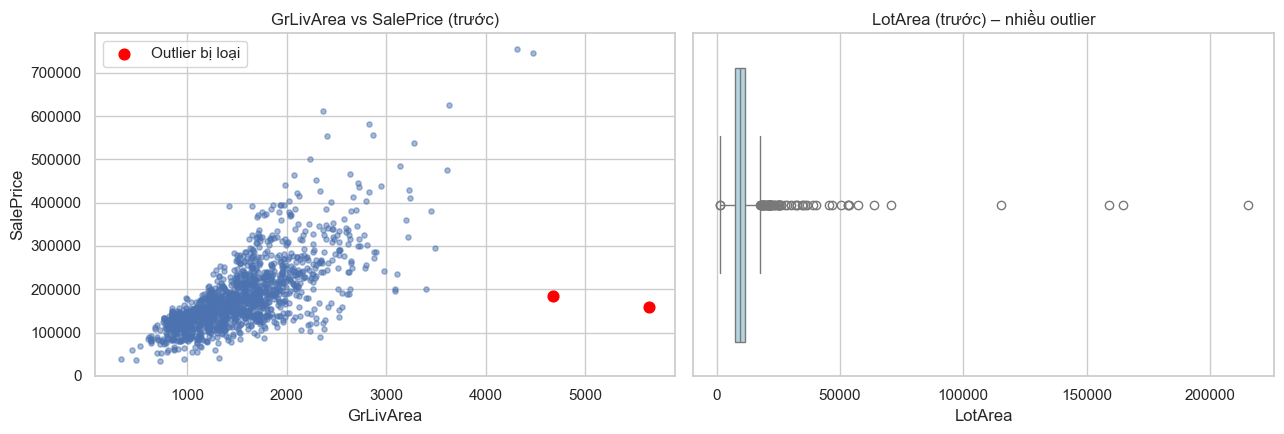

Số dòng bị loại: 2


In [7]:
# Trực quan hóa outlier GrLivArea - SalePrice
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(train['GrLivArea'], train[TARGET], alpha=.5, s=14)
bad = (train['GrLivArea'] > 4000) & (train[TARGET] < 300000)
ax[0].scatter(train.loc[bad,'GrLivArea'], train.loc[bad,TARGET], c='red', s=60, label='Outlier bị loại')
ax[0].set(title='GrLivArea vs SalePrice (trước)', xlabel='GrLivArea', ylabel='SalePrice'); ax[0].legend()
sns.boxplot(x=train['LotArea'], ax=ax[1], color='lightblue'); ax[1].set_title('LotArea (trước) – nhiều outlier')
plt.tight_layout(); plt.show()
print('Số dòng bị loại:', bad.sum())

In [8]:
# --- 4.1 Loại outlier vô lý khỏi train
keep = ~((train['GrLivArea'] > 4000) & (train[TARGET] < 300000))
full_train = full.iloc[:n_train][keep.values].reset_index(drop=True)
y = train.loc[keep, TARGET].reset_index(drop=True)
full_test = full.iloc[n_train:].reset_index(drop=True)
print('Train sau khi loại outlier:', full_train.shape)

# --- 4.2 Capping IQR (fence tính từ train)
# chỉ áp dụng cho biến số liên tục, KHÔNG áp dụng cho biến rời rạc/năm/mã
cont_cols = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF',
             '1stFlrSF','2ndFlrSF','LowQualFinSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF',
             'EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal']
fences = {}
for c in cont_cols:
    q1, q3 = full_train[c].quantile([.25, .75]); i = q3 - q1
    fences[c] = (q1 - 3*i, q3 + 3*i)

# cột có phần lớn là 0 (IQR=0) -> fence suy biến; dùng percentile 99.5 thay thế
for c in cont_cols:
    lo, hi = fences[c]
    if hi - lo == 0 or full_train[c].quantile(.75) == 0:
        fences[c] = (full_train[c].min(), full_train[c].quantile(.995))

capped = {}
for c in cont_cols:
    lo, hi = fences[c]
    n = int(((full_train[c] < lo) | (full_train[c] > hi)).sum() + ((full_test[c] < lo) | (full_test[c] > hi)).sum())
    capped[c] = n
    full_train[c] = full_train[c].clip(lo, hi); full_test[c] = full_test[c].clip(lo, hi)
print('Số giá trị bị cap:'); pd.Series(capped)[lambda s: s>0].sort_values(ascending=False)

Train sau khi loại outlier: (1458, 80)
Số giá trị bị cap:


MasVnrArea       54
LotArea          51
OpenPorchSF      34
LotFrontage      19
MiscVal          19
EnclosedPorch    18
3SsnPorch        13
BsmtFinSF2       13
ScreenPorch      13
PoolArea         12
LowQualFinSF     11
WoodDeckSF        7
TotalBsmtSF       5
GarageArea        5
GrLivArea         4
1stFlrSF          3
BsmtFinSF1        1
dtype: int64

## 5. Xử lý Categorical Data
- **Ordinal** (có thứ tự chất lượng: `Ex > Gd > TA > Fa > Po > None`) → mã hóa số theo thứ tự để giữ thông tin thứ hạng.
- **Biến số nhưng bản chất là nhãn** (`MSSubClass`, `MoSold`, `YrSold`) → chuyển thành categorical.
- **Nominal** (Neighborhood, MSZoning...) → **One-Hot Encoding** (không tạo thứ tự giả).

In [9]:
qual = {'None':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5}
ordinal_maps = {
    **{c: qual for c in ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC','KitchenQual',
                         'FireplaceQu','GarageQual','GarageCond','PoolQC']},
    'BsmtExposure': {'None':0,'No':1,'Mn':2,'Av':3,'Gd':4},
    'BsmtFinType1': {'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'BsmtFinType2': {'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'GarageFinish': {'None':0,'Unf':1,'RFn':2,'Fin':3},
    'Fence':        {'None':0,'MnWw':1,'GdWo':2,'MnPrv':3,'GdPrv':4},
    'LotShape':     {'IR3':0,'IR2':1,'IR1':2,'Reg':3},
    'LandSlope':    {'Sev':0,'Mod':1,'Gtl':2},
    'CentralAir':   {'N':0,'Y':1},
    'PavedDrive':   {'N':0,'P':1,'Y':2},
    'Functional':   {'Sal':0,'Sev':1,'Maj2':2,'Maj1':3,'Mod':4,'Min2':5,'Min1':6,'Typ':7},
    'Utilities':    {'ELO':0,'NoSeWa':1,'NoSewr':2,'AllPub':3},
}
for df in (full_train, full_test):
    for c, m in ordinal_maps.items(): df[c] = df[c].map(m).astype(int)
    for c in ['MSSubClass','MoSold','YrSold']: df[c] = df[c].astype(str)

# Feature engineering nhẹ (tổng hợp, giảm đa cộng tuyến giữa các biến diện tích)
for df in (full_train, full_test):
    df['TotalSF']    = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath']  = df['FullBath'] + .5*df['HalfBath'] + df['BsmtFullBath'] + .5*df['BsmtHalfBath']
    df['HouseAge']   = df['YearBuilt'].astype(int).rsub(2010)
    df['HasPool']    = (df['PoolArea'] > 0).astype(int)
    df['HasGarage']  = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt']    = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)

nominal_cols = full_train.select_dtypes(exclude='number').columns.tolist()
print(f'{len(nominal_cols)} cột nominal sẽ one-hot:', nominal_cols[:8], '...')

25 cột nominal sẽ one-hot: ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1'] ...


In [10]:
# --- 4.3 log1p cho biến lệch mạnh (skew tính từ train), sau đó One-Hot
num_now = full_train.select_dtypes(include='number').columns.drop('Id')
binary_like = [c for c in num_now if full_train[c].nunique() <= 2]
skew_s = full_train[num_now].drop(columns=binary_like).apply(lambda s: skew(s)).sort_values(ascending=False)
# chỉ log hóa biến liên tục (>10 giá trị khác nhau) và lệch DƯƠNG; log1p làm xấu thêm biến lệch âm / biến rời rạc
skewed = [c for c in skew_s[skew_s > 0.75].index if full_train[c].nunique() > 10]
print(f'{len(skewed)} biến liên tục lệch dương được log1p:', skewed)
skew_before_log = skew_s[skewed].copy()
for df in (full_train, full_test):
    for c in skewed: df[c] = np.log1p(df[c].clip(lower=0))
y_log = np.log1p(y)

# --- 5. One-Hot (căn cột train/test giống nhau)
both = pd.concat([full_train.assign(_s='tr'), full_test.assign(_s='te')], ignore_index=True)
both = pd.get_dummies(both, columns=nominal_cols, drop_first=True, dtype=int)
X_train = both[both['_s']=='tr'].drop(columns=['_s','Id']).reset_index(drop=True)
X_test  = both[both['_s']=='te'].drop(columns=['_s']).reset_index(drop=True)
test_ids = X_test.pop('Id')
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Còn missing?', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print('Còn cột object?', X_train.select_dtypes(exclude='number').shape[1])

16 biến liên tục lệch dương được log1p: ['LowQualFinSF', '3SsnPorch', 'MiscVal', 'BsmtFinSF2', 'ScreenPorch', 'EnclosedPorch', 'MasVnrArea', 'OpenPorchSF', 'WoodDeckSF', 'LotArea', 'BsmtUnfSF', 'GrLivArea', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'TotalSF']
X_train: (1458, 235) | X_test: (1459, 235)
Còn missing? 0 0
Còn cột object? 0


## 6. So sánh TRƯỚC và SAU preprocessing
### 6.1 Bảng tổng quan

In [11]:
num_after = [c for c in X_train.columns if X_train[c].nunique() > 2]
after = {
    'shape': X_train.shape,
    'missing_cells': int(X_train.isna().sum().sum()),
    'cols_with_missing': int((X_train.isna().sum() > 0).sum()),
    'object_cols': X_train.select_dtypes(exclude='number').shape[1],
    'outliers_iqr_total': int(iqr_outlier_count(X_train, [c for c in cont_cols]).sum()),
    'skew_target': float(y_log.skew()),
    'mean_abs_skew_num': float(X_train[num_after].skew().abs().mean()),
}
cmp = pd.DataFrame({'TRƯỚC': before, 'SAU': after})
cmp.loc['outliers_iqr_total','TRƯỚC'] = int(iqr_outlier_count(train_raw, cont_cols).sum())  # cùng tập cột để so công bằng
cmp

,TRƯỚC,SAU
shape,"(1460, 81)","(1458, 235)"
missing_cells,7829,0
cols_with_missing,19,0
object_cols,43,0
outliers_iqr_total,1133,1030
skew_target,1.882876,0.12158
mean_abs_skew_num,3.196489,1.903184


> **Lưu ý:** `outliers_iqr_total` đếm theo ngưỡng 1.5·IQR trên các cột diện tích liên tục. Sau preprocessing số này giảm ít vì ta chỉ cap ở 3·IQR (chỉ cắt giá trị cực đoan) và nhiều cột có đa số giá trị bằng 0 nên IQR rất nhỏ; log1p còn làm dịch thang đo. Hiệu quả thực của xử lý outlier thể hiện rõ hơn ở biểu đồ và `skew` bên dưới.

### 6.2 Dữ liệu thiếu – trước vs sau

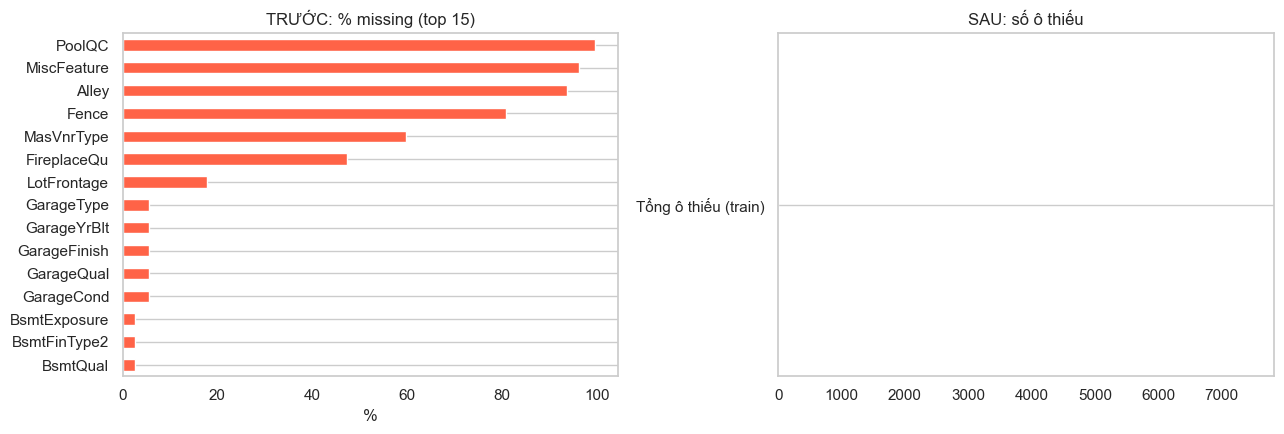

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
mt.head(15)['pct'][::-1].plot.barh(ax=ax[0], color='tomato'); ax[0].set(title='TRƯỚC: % missing (top 15)', xlabel='%')
ax[1].barh(['Tổng ô thiếu (train)'], [after['missing_cells']], color='seagreen'); ax[1].set(title='SAU: số ô thiếu', xlim=(0, max(1, before['missing_cells'])))
for a in ax: a.grid(axis='x')
plt.tight_layout(); plt.show()

### 6.3 Outlier & phân phối – trước vs sau

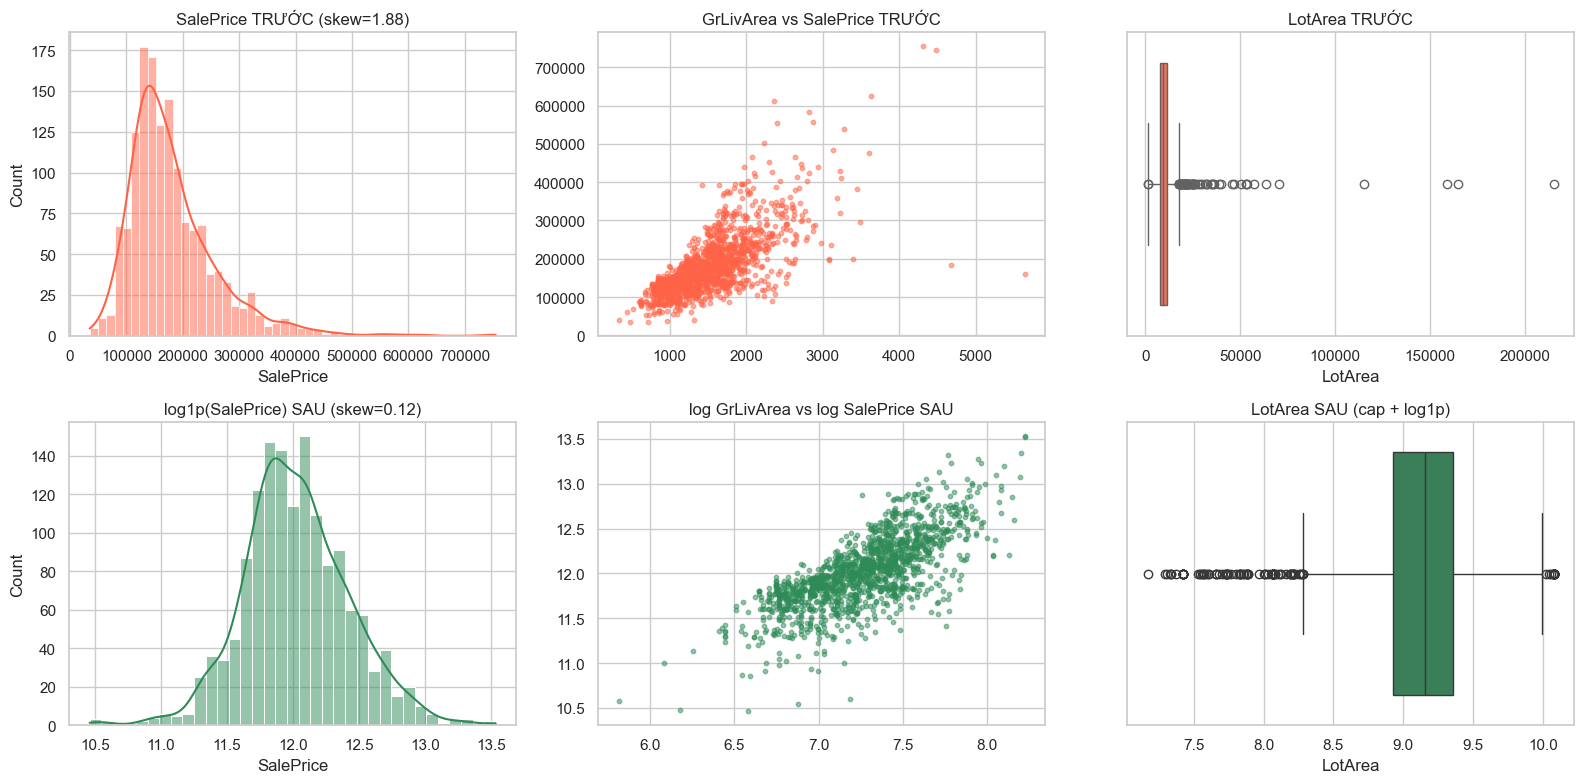

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
# Target
sns.histplot(train_raw[TARGET], kde=True, ax=ax[0,0], color='tomato'); ax[0,0].set_title(f'SalePrice TRƯỚC (skew={train_raw[TARGET].skew():.2f})')
sns.histplot(y_log, kde=True, ax=ax[1,0], color='seagreen');           ax[1,0].set_title(f'log1p(SalePrice) SAU (skew={y_log.skew():.2f})')
# GrLivArea
ax[0,1].scatter(train_raw['GrLivArea'], train_raw[TARGET], s=10, alpha=.5, c='tomato'); ax[0,1].set_title('GrLivArea vs SalePrice TRƯỚC')
ax[1,1].scatter(X_train['GrLivArea'], y_log, s=10, alpha=.5, c='seagreen');             ax[1,1].set_title('log GrLivArea vs log SalePrice SAU')
# LotArea
sns.boxplot(x=train_raw['LotArea'], ax=ax[0,2], color='tomato');      ax[0,2].set_title('LotArea TRƯỚC')
sns.boxplot(x=X_train['LotArea'], ax=ax[1,2], color='seagreen');      ax[1,2].set_title('LotArea SAU (cap + log1p)')
plt.tight_layout(); plt.show()

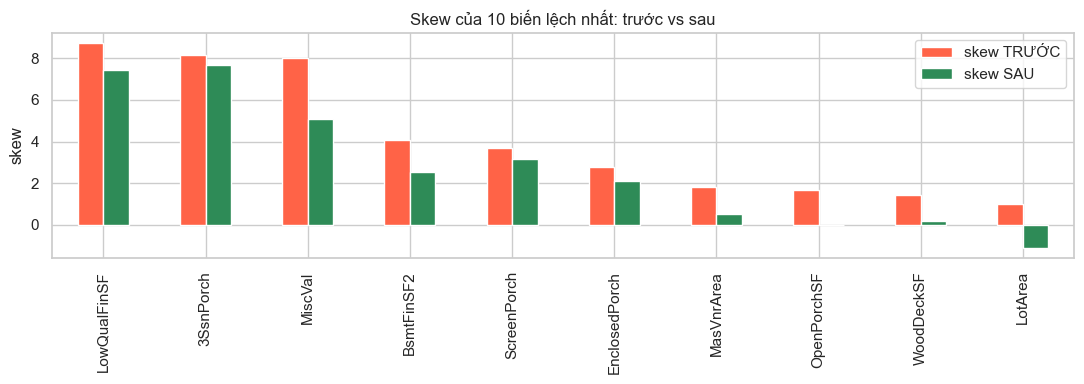

,skew TRƯỚC,skew SAU
LowQualFinSF,8.74,7.44
3SsnPorch,8.15,7.67
MiscVal,8.02,5.09
BsmtFinSF2,4.06,2.52
ScreenPorch,3.71,3.14
EnclosedPorch,2.80,2.11
MasVnrArea,1.81,0.50
OpenPorchSF,1.69,-0.03
WoodDeckSF,1.45,0.16
LotArea,0.98,-1.10


In [14]:
# Độ lệch (skew) của các biến bị biến đổi nhiều nhất
top = skew_before_log.abs().sort_values(ascending=False).head(10).index
sk = pd.DataFrame({'skew TRƯỚC': skew_before_log[top],
                   'skew SAU': X_train[top].apply(lambda s: skew(s))}).round(2)
sk.plot.bar(figsize=(11,4), color=['tomato','seagreen']); plt.title('Skew của 10 biến lệch nhất: trước vs sau'); plt.ylabel('skew'); plt.tight_layout(); plt.show()
sk

### 6.4 Hiệu năng mô hình – trước vs sau
Để so sánh công bằng, dùng cùng 5-fold CV và đo **RMSE trên log(SalePrice)** (chuẩn đánh giá của bài toán).

- **TRƯỚC:** dữ liệu thô tối thiểu – chỉ giữ cột số, điền median (vì mô hình không nhận `NaN`/chuỗi), không xử lý outlier, không encode categorical, target ở thang gốc rồi log hóa để đo cùng thước.
- **SAU:** dữ liệu sau toàn bộ pipeline ở trên.

In [15]:
kf = KFold(5, shuffle=True, random_state=42)
y_raw_log = np.log1p(train_raw[TARGET])

def cv_rmse(model, X, y_true_log):
    s = cross_val_score(model, X, y_true_log, scoring='neg_root_mean_squared_error', cv=kf)
    return -s.mean(), s.std()

X_before = train_raw[num_cols_raw]   # chỉ numeric thô, còn NaN
ridge = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10))
rf    = lambda: make_pipeline(SimpleImputer(strategy='median'), RandomForestRegressor(300, n_jobs=-1, random_state=42))

res = []
for name, mk in [('Ridge', ridge), ('RandomForest', rf)]:
    b = cv_rmse(mk(), X_before, y_raw_log)
    a = cv_rmse(mk(), X_train, y_log)
    res.append({'Model': name, 'RMSE_log TRƯỚC': b[0], 'RMSE_log SAU': a[0],
                'Cải thiện (%)': (b[0]-a[0])/b[0]*100, 'Số feature TRƯỚC': X_before.shape[1], 'Số feature SAU': X_train.shape[1]})
res = pd.DataFrame(res).round(4); res

,Model,RMSE_log TRƯỚC,RMSE_log SAU,Cải thiện (%),Số feature TRƯỚC,Số feature SAU
0,Ridge,0.1596,0.1266,20.6769,36,235
1,RandomForest,0.1473,0.1364,7.3965,36,235


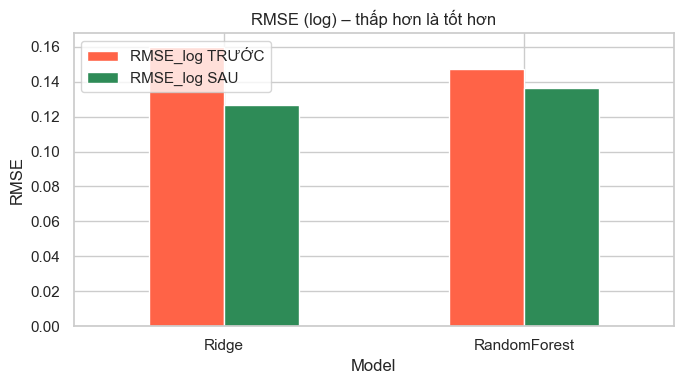

In [16]:
ax = res.set_index('Model')[['RMSE_log TRƯỚC','RMSE_log SAU']].plot.bar(figsize=(7,4), color=['tomato','seagreen'], rot=0)
ax.set_title('RMSE (log) – thấp hơn là tốt hơn'); ax.set_ylabel('RMSE'); plt.tight_layout(); plt.show()

### 6.5 Nhận xét
Xem bảng ở 6.1 và 6.4 để đối chiếu số liệu cụ thể sau khi chạy. Các thay đổi chính:

- **Missing:** từ hàng nghìn ô thiếu (19 cột ở train, 33 cột ở test) về **0**; phần lớn `NaN` thực chất là "không có tính năng" nên được giữ lại thông tin bằng `None`/`0` thay vì bị xóa.
- **Bất thường:** các lỗi logic về năm (ví dụ `GarageYrBlt` trong tương lai ở test) được sửa nên không còn mâu thuẫn thời gian.
- **Outlier:** loại 2 điểm ngoại lai ảnh hưởng mạnh ở train, cap các giá trị cực đoan và log hóa giúp **skew của target và các biến diện tích giảm rõ rệt**, phân phối gần chuẩn hơn.
- **Categorical:** toàn bộ cột chuỗi được mã hóa số (ordinal giữ thứ tự, nominal one-hot) → số cột tăng, nhưng mô hình dùng được **toàn bộ thông tin** (đặc biệt `Neighborhood`, `ExterQual`, `KitchenQual`... vốn rất quan trọng với giá nhà).
- **Mô hình:** RMSE trên log giảm đáng kể so với dữ liệu thô, chứng tỏ preprocessing có tác dụng thực sự.

## 7. Lưu dữ liệu đã xử lý

In [17]:
out_train = X_train.copy(); out_train.insert(0, 'Id', train_raw.loc[keep, 'Id'].values); out_train['SalePrice_log'] = y_log.values
out_test  = X_test.copy();  out_test.insert(0, 'Id', test_ids.values)
out_train.to_csv('train_processed.csv', index=False)
out_test.to_csv('test_processed.csv', index=False)
print('Đã lưu:', out_train.shape, out_test.shape)
print('Lưu ý: SalePrice_log = log1p(SalePrice). Khi dự đoán, đổi về giá thật bằng np.expm1(pred).')

Đã lưu: (1458, 237) (1459, 236)
Lưu ý: SalePrice_log = log1p(SalePrice). Khi dự đoán, đổi về giá thật bằng np.expm1(pred).
